# Chronological stockout prediction

In [1]:
from pathlib import Path
import sys
import duckdb, pandas as pd, matplotlib.pyplot as plt
root=next(path for path in [Path.cwd(), *Path.cwd().parents] if (path/'config/default.json').exists())
sys.path.insert(0,str(root))
output=root/'artifacts'
figures=root/'reports/figures'
db=duckdb.connect(str(output/'operations.duckdb'),read_only=True,config={'threads':2})
def read(name):
    return pd.read_csv(output/f'{name}.csv')

,model,selected,validation_ap,threshold,pr_auc,roc_auc,precision,recall,f1,brier,precision_at_5pct,recall_at_5pct,tn,fp,fn,tp,observations,prevalence
0,rules,False,0.834498,0.278874,0.894717,0.881068,0.766644,0.951262,0.849033,0.172765,0.951944,0.081396,17706,12191,2052,40051,72000,0.584764
1,logistic,False,0.878959,0.440381,0.925423,0.905529,0.805503,0.919911,0.858914,0.120022,0.994167,0.085006,20545,9352,3372,38731,72000,0.584764
2,forest,False,0.876232,0.418271,0.923942,0.904897,0.797535,0.931288,0.859237,0.120138,0.991111,0.084745,19943,9954,2893,39210,72000,0.584764
3,lightgbm_15,False,0.882599,0.419857,0.924050,0.904622,0.806639,0.919982,0.859590,0.120234,0.990278,0.084673,20612,9285,3369,38734,72000,0.584764
4,lightgbm_31,True,0.882845,0.439928,0.924549,0.904665,0.812475,0.909579,0.858289,0.120436,0.992500,0.084863,21058,8839,3807,38296,72000,0.584764


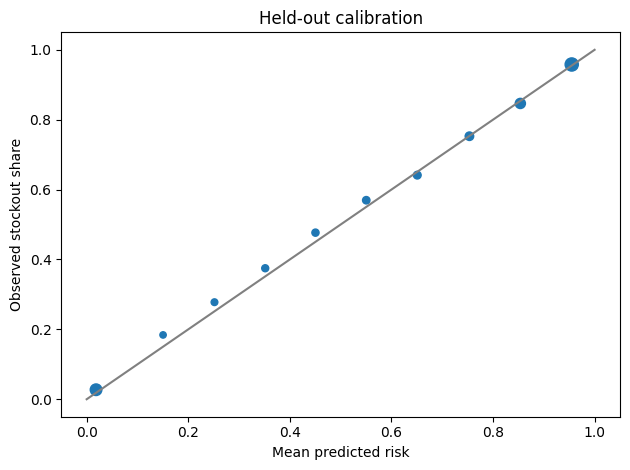

In [2]:
display(read('metrics'))
s = read('calibration')
plt.plot([0,1],[0,1],color='gray')
plt.scatter(s.risk,s.actual,s=10+80*s['count']/s['count'].max())
plt.xlabel('Mean predicted risk')
plt.ylabel('Observed stockout share')
plt.title('Held-out calibration')
plt.tight_layout()
plt.savefig(figures/'calibration.png',dpi=130)
plt.show()

The training, validation, and test periods are chronological. Thresholds and the winner are selected using validation only. The top-5% metrics estimate intervention triage quality.